<a href="https://colab.research.google.com/github/thaopham29/Actuarial-Modeling-A-Data-Science-Upgrade/blob/main/data_description_and_preparation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Introduction of data

The dataset is based on a Belgian motor insurance portfolio from 1997 and is provided by the Casualty Actuarial Society (CAS). The data contains 163212 rows (observations) and 18 columns (variables). Specifically,



*   id: Policy identification
*   expo: exposure, defined in yearly unit, within (0, 1]

* claim: binary indicator, take only value 0 (the policy has no claim) or 1 (the policy has at least 1 claim)
*   nclaims: actual number of claims from a policy during the exposure


*   amounts: total claim severity of all claims occured during the exposure period
*   average: average amount of claim severity. When the policyholder has no claim, the variable takes NaN.


*  coverage:factor data type with 3 levels: TPL, TPL+, TPL++.
*   ageph: age of the policy in years


*  sex: factor data type with 2 levels: male and female.
*  bm: bonus-malus level

*   power: engine power of the car

*   agec: age of the car in years

*   fuel: factor data type with 2 levels: "gasoline","diesel".

*   use: factor data type with 2 levels: "private", "work"

*   fleet: factor data type, indicates whether the vehicle belongs to a fleet policy, with 2 levels: 1 (yes) and 0 (no)

*   postcode: Residential area of the policy

*   lat, long: Geographic location of the insured vehicle


One key consideration is that each cell represents a policy or policyholder, not an individual claim. Therefore, with this dataset, individual claim amount is unavailable, (or only available for those who has only one claim per respective exposure), total claim amount and average claim amount are otherwise used to model.
























In [ ]:
download.file(
  "https://raw.githubusercontent.com/dutangc/CASdatasets/master/data/beMTPL97.rda",
  destfile = "beMTPL97.rda",
  mode = "wb"
)

load("beMTPL97.rda")

ls()
data_be <- as.data.frame(beMTPL97)

head(data_be)
str(data_be)

[1] "beMTPL97"

,id,expo,claim,nclaims,amount,average,coverage,ageph,sex,bm,power,agec,fuel,use,fleet,postcode,long,lat
,<int>,<dbl>,<fct>,<int>,<dbl>,<dbl>,<fct>,<int>,<fct>,<int>,<int>,<int>,<fct>,<fct>,<fct>,<int>,<dbl>,<dbl>
1,1,1.00000000,1,1,1618.0010,1618.0010,TPL,50,male,5,77,12,gasoline,private,0,1000,4.355223,50.84539
2,2,1.00000000,0,0,0.0000,NaN,TPL+,64,female,5,66,3,gasoline,private,0,1000,4.355223,50.84539
3,3,1.00000000,0,0,0.0000,NaN,TPL,60,male,0,70,10,diesel,private,0,1000,4.355223,50.84539
4,4,1.00000000,0,0,0.0000,NaN,TPL,77,male,0,57,15,gasoline,private,0,1000,4.355223,50.84539
5,5,0.04657534,1,1,155.9746,155.9746,TPL,28,female,9,70,7,gasoline,private,0,1000,4.355223,50.84539
6,6,1.00000000,0,0,0.0000,NaN,TPL,26,male,11,70,12,gasoline,private,0,1000,4.355223,50.84539


'data.frame':	163212 obs. of  18 variables:
 $ id      : int  1 2 3 4 5 6 7 8 9 10 ...
 $ expo    : num  1 1 1 1 0.0466 ...
 $ claim   : Factor w/ 2 levels "0","1": 2 1 1 1 2 1 2 1 1 1 ...
 $ nclaims : int  1 0 0 0 1 0 1 0 0 0 ...
 $ amount  : num  1618 0 0 0 156 ...
 $ average : num  1618 NaN NaN NaN 156 ...
 $ coverage: Factor w/ 3 levels "TPL","TPL+","TPL++": 1 2 1 1 1 1 3 1 3 2 ...
 $ ageph   : int  50 64 60 77 28 26 26 58 59 34 ...
 $ sex     : Factor w/ 2 levels "female","male": 2 1 2 2 1 2 2 1 2 2 ...
 $ bm      : int  5 5 0 0 9 11 11 11 0 7 ...
 $ power   : int  77 66 70 57 70 70 55 47 98 74 ...
 $ agec    : int  12 3 10 15 7 12 8 14 3 6 ...
 $ fuel    : Factor w/ 2 levels "gasoline","diesel": 1 1 2 1 1 1 1 1 1 1 ...
 $ use     : Factor w/ 2 levels "private","work": 1 1 1 1 1 1 1 1 1 1 ...
 $ fleet   : Factor w/ 2 levels "0","1": 1 1 1 1 1 1 1 1 1 1 ...
 $ postcode: int  1000 1000 1000 1000 1000 1000 1000 1000 1000 1000 ...
 $ long    : num  4.36 4.36 4.36 4.36 4.36 ...
 $ lat 

# Initial data checking and cleaning (if necessary)

Before working with the data, checking the missing value and logical consistency of all variables are crucial. Across all the columns (variables) only average has NaN values, as when the policyholder has no claim during the exposure period, the average claim amount is set to NaN. Specifically, 89% of the cells have value NaN, that means 89% of the portfolio has no claims during repective exposure.

In [ ]:
library(dplyr)
validation_report <- data.frame(
  Check = c(
    "Exposure values are positive",
    "Claim counts are non-negative",
    "Claim counts are integers",
    "Claim amounts are non-negative",
    "Latitude is within valid range",
    "Longitude is within valid range",
    "Claim indicator matches claim count",
    "Zero claims but positive claim amount",
    "Positive claims but zero claim amount"
  ),

  Violations = c(
    sum(data_be$expo <= 0, na.rm = TRUE),

    sum(data_be$claims < 0, na.rm = TRUE),

    sum(data_be$nclaims %% 1 != 0, na.rm = TRUE),

    sum(data_be$amount < 0, na.rm = TRUE),

    sum(data_be$lat < -90 | data_be$lat > 90, na.rm = TRUE),

    sum(data_be$long < -180 | data_be$long > 180, na.rm = TRUE),

    sum(data_be$Claim != as.integer(data_be$nclaims > 0), na.rm = TRUE),

    sum(data_be$nclaims == 0 & data_be$amount > 0, na.rm = TRUE),

    sum(data_be$nclaims > 0 & data_be$amount == 0, na.rm = TRUE)
  )
)

validation_report



Check,Violations
<chr>,<int>
Exposure values are positive,0
Claim counts are non-negative,0
Claim counts are integers,0
Claim amounts are non-negative,0
Latitude is within valid range,0
Longitude is within valid range,0
Claim indicator matches claim count,0
Zero claims but positive claim amount,0
Positive claims but zero claim amount,0


# Exploratory data analysis


## Portfolio characteristics

Firstly, some important variables in my study will be briefly examined, in order to choose the most appropriate ones for the model. One of the most important variable in actuarial model is exposure (expo in the data), which represent the fraction of observation period that the policy is insured. The code below shows the histogram and some important statistics of the exposure

Number_of_policies,Mean,Median,SD,Minimum,Maximum
<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
163212,0.8897436,1,0.244202,0.002739726,1


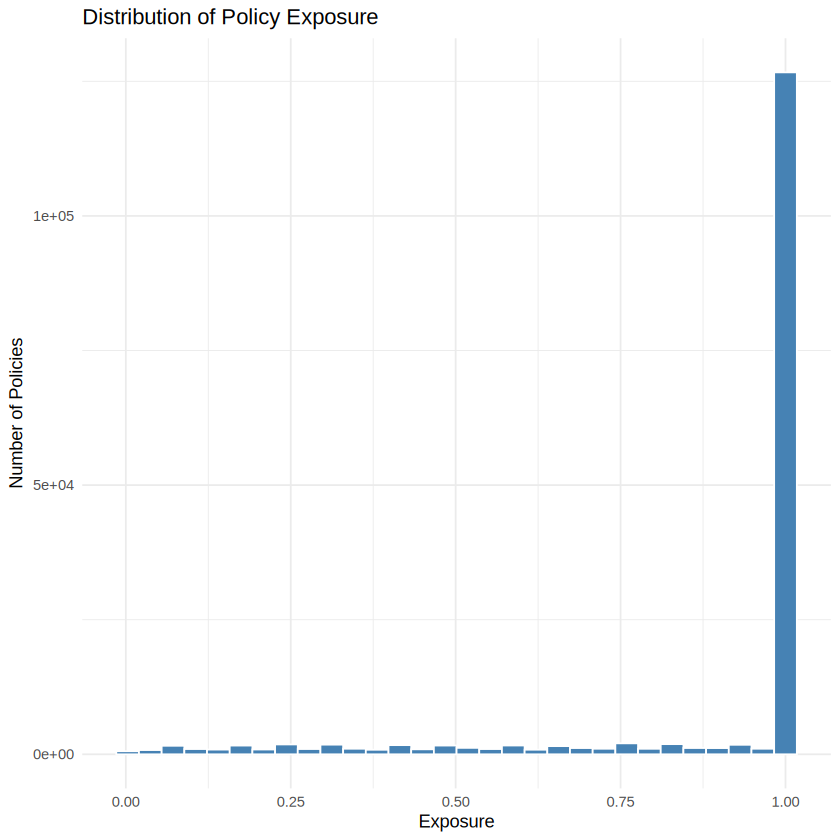

In [ ]:
library(dplyr)
library(ggplot2)
library(tidyr)
#Distribtuion of Exposure
exposure_summary <- data_be %>%
  summarise(
    Number_of_policies = sum(!is.na(expo)),
    Mean = mean(expo, na.rm = TRUE),
    Median = median(expo, na.rm = TRUE),
    SD = sd(expo, na.rm = TRUE),
    Minimum = min(expo, na.rm = TRUE),
    Maximum = max(expo, na.rm = TRUE)
  )

exposure_summary
# Histogram of exposure
ggplot(data_be, aes(x = expo)) +
  geom_histogram(
    bins = 30,
    fill = "steelblue",
    color = "white"
  ) +
  labs(
    title = "Distribution of Policy Exposure",
    x = "Exposure",
    y = "Number of Policies"
  ) +
  theme_minimal()

## Claim frequency

Claim_status,Number_of_policies,Percentage
<chr>,<int>,<dbl>
Without claim,144936,88.8
With claim,18276,11.2


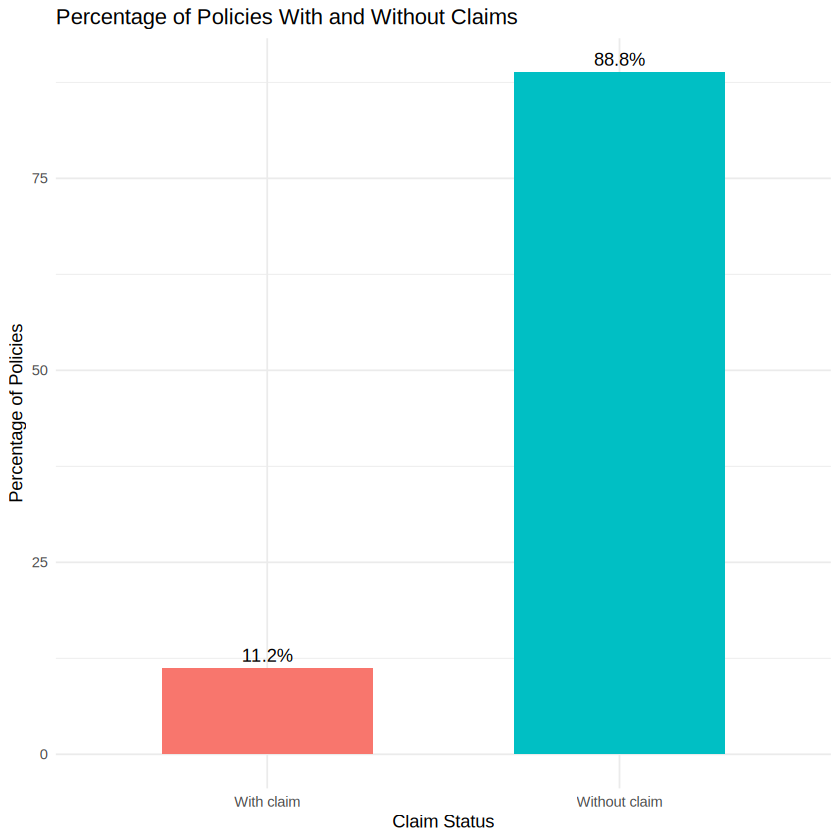

In [ ]:
# Exploratory data analysis
##Number of policies with and without claims##
# Exploratory data analysis
##Number of policies with and without claims##
claim_summary <- data_be %>%
  filter(!is.na(claim)) %>%
  group_by(claim) %>%
  summarise(
    Number_of_policies = n(),
    .groups = "drop"
  ) %>%
  mutate(
    Percentage = round(
      Number_of_policies / sum(Number_of_policies) * 100, 2
    ),
    Claim_status = ifelse(claim == 1, "With claim", "Without claim")
  ) %>%
  select(Claim_status, Number_of_policies, Percentage)

claim_summary

ggplot(claim_summary,
       aes(x = Claim_status, y = Percentage, fill = Claim_status)) +
  geom_col(width = 0.6) +
  geom_text(
    aes(label = paste0(Percentage, "%")),
    vjust = -0.5
  ) +
  labs(
    title = "Percentage of Policies With and Without Claims",
    x = "Claim Status",
    y = "Percentage of Policies"
  ) +
  theme_minimal() +
  theme(legend.position = "none")



First, the number and percentage of the policies have claims will be determined, which shows in the code. Specifically, 11.2% policies have claims during the exposure. The distribution of claim frequency and some imporatant statistics (mean, variance, standard deviation) will then be illustrated. There are only 2 policies have 5 claims.

nclaims,Number_of_policies,Percentage
<int>,<int>,<dbl>
0,144936,88.80
1,16539,10.13
2,1556,0.95
3,162,0.10
4,17,0.01
5,2,0.00


Mean_claim_count,Variance_claim_count,Standard_deviation,Maximum_claim_count
<dbl>,<dbl>,<dbl>,<int>
0.1238573,0.1350352,0.3674713,5


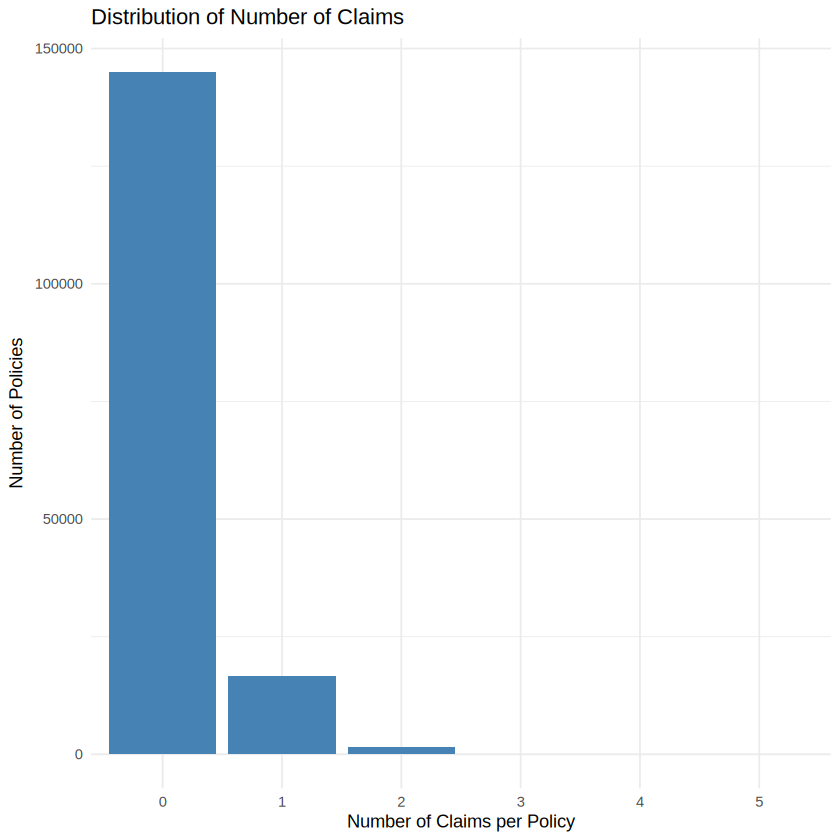

In [ ]:
##frequency distribution of claim frequencies
frequency_distribution <- data_be %>%
  filter(!is.na(nclaims)) %>%
  group_by(nclaims) %>%
  summarise(
    Number_of_policies = n(),
    .groups = "drop"
  ) %>%
  mutate(
    Percentage = round(
      Number_of_policies / sum(Number_of_policies) * 100, 2
    )
  ) %>%
  arrange(nclaims)

frequency_distribution
#Visualisation
ggplot(data_be, aes(x = factor(nclaims))) +
  geom_bar(fill = "steelblue") +
  labs(
    title = "Distribution of Number of Claims",
    x = "Number of Claims per Policy",
    y = "Number of Policies"
  ) +
  theme_minimal()

## Some statistics
count_statistics <- data_be %>%
  filter(!is.na(nclaims)) %>%
  summarise(
    Mean_claim_count = mean(nclaims),
    Variance_claim_count = var(nclaims),
    Standard_deviation = sd(nclaims),
    Maximum_claim_count = max(nclaims)
  )

count_statistics



The empirical mean value is  0.1238573 and the variance is 0.1350352, just slightly higher than the mean value. Therefore, Poisson distribution will be appropriate starting point to modell the frequency of claim counts, as in Poisson distribution the mean value is equal to variance.

## (Policy - level) Claim severity

## Relationship between variables
